# Crop Yield Prediction — Data Cleaning and Preprocessing

## 1. Introduction

In the previous notebook, we performed Exploratory Data Analysis to understand the crop yield dataset.

From the EDA, we identified that:

- The dataset contains no missing values.
- The dataset contains duplicate rows.
- `Area` and `Item` are categorical features.
- `hg/ha_yield` is the target variable.
- Numerical features have different value ranges.

In this notebook, we clean and preprocess the dataset so it can be used for machine learning model building.

## Objectives

The main objectives of this notebook are:

- Load the original dataset
- Remove duplicate records
- Separate input features and target variable
- Encode categorical variables
- Split the dataset into training and testing sets
- Scale numerical features

## 1. Imports, Load Raw Data and Import Utility Functions

In this section, we import the required libraries and load the original crop yield dataset.

We also import helper functions from `utils.py`:

- `load_data()` is used to load the dataset.
- `preprocess_data()` will be used later for duplicate removal and categorical encoding.

The raw dataset is loaded before applying any cleaning or preprocessing steps.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sys
import os

# Ignore warning messages for cleaner notebook output
warnings.filterwarnings("ignore")

# Add src folder path to access utils.py
sys.path.insert(0, os.path.abspath("../src"))

# Import utility functions
from utils import load_data, preprocess_data

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


pd.set_option("display.max_columns", None)


df = load_data("../data/yield_df.csv")

# Display dataset information
print("Raw dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


df.head()

Raw dataset loaded successfully!
Number of rows: 28242
Number of columns: 7


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


## 2. Missing Values and Duplicate Records

Before cleaning the dataset, we check for missing values and duplicate records.

From the previous EDA notebook, we found:

- There are no missing values.
- There are duplicate rows in the dataset.

Duplicate rows should be removed before model building because repeated records can unfairly influence the training process.

In [2]:
# Check missing values and duplicate records

missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df) * 100).round(2)

print("Missing Values")
print("-" * 40)
display(missing_values)

print("\nDuplicate Records")
print("-" * 40)
print("Number of duplicate rows:", duplicate_count)
print("Duplicate percentage:", duplicate_percentage, "%")

print("\nColumn Names")
print("-" * 40)
print(df.columns.tolist())

Missing Values
----------------------------------------


,Missing Values,Percentage
Area,0,0.0
Item,0,0.0
Year,0,0.0
hg/ha_yield,0,0.0
average_rain_fall_mm_per_year,0,0.0
pesticides_tonnes,0,0.0
avg_temp,0,0.0



Duplicate Records
----------------------------------------
Number of duplicate rows: 2310
Duplicate percentage: 8.18 %

Column Names
----------------------------------------
['Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


In [3]:
# Display basic statistical summary

df.describe(include="all").round(2)

,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,28242,28242,28242.00,28242.00,28242.00,28242.00,28242.00
unique,101,10,NaN,NaN,NaN,NaN,NaN
top,India,Potatoes,NaN,NaN,NaN,NaN,NaN
freq,4048,4276,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,2001.54,77053.33,1149.06,37076.91,20.54
std,NaN,NaN,7.05,84956.61,709.81,59958.78,6.31
min,NaN,NaN,1990.00,50.00,51.00,0.04,1.30
25%,NaN,NaN,1995.00,19919.25,593.00,1702.00,16.70
50%,NaN,NaN,2001.00,38295.00,1083.00,17529.44,21.51
75%,NaN,NaN,2008.00,104676.75,1668.00,48687.88,26.00


### Observations

From the initial data quality check:

- The dataset contains **0 missing values**.
- The dataset contains **2,310 duplicate rows**.
- All columns have suitable data types for the next preprocessing steps.
- Duplicate rows should be removed before separating features and target variable.

The next step is to create a cleaned dataset by removing duplicate records.

## 3. Duplicate Removal and One-Hot Encoding

In this section, we prepare the dataset for machine learning.

The preprocessing step includes:

- Removing duplicate rows
- Encoding categorical columns
- Converting boolean dummy columns into integer values

The dataset contains two categorical columns:

- `Area` — country or region
- `Item` — crop type

Since these columns are nominal categorical variables, they do not have a natural order. Therefore, we use **one-hot encoding** to convert them into numerical columns.

We use `drop_first=True` to avoid the dummy variable trap and reduce multicollinearity.

In [4]:
# Apply preprocessing using utility function

print("Before preprocessing")
print("-" * 40)
print("Shape:", df.shape)
print("Unique countries/areas:", df["Area"].nunique())
print("Unique crop types:", df["Item"].nunique())
print("Crop types:", sorted(df["Item"].unique()))

# Apply preprocessing
df_clean = preprocess_data(df)

print("\nAfter preprocessing")
print("-" * 40)
print("Shape:", df_clean.shape)
print("Rows after duplicate removal:", df_clean.shape[0])
print("Total columns after encoding:", df_clean.shape[1])

print("\nData type counts")
print("-" * 40)
display(df_clean.dtypes.value_counts())

Before preprocessing
----------------------------------------
Shape: (28242, 7)
Unique countries/areas: 101
Unique crop types: 10
Crop types: ['Cassava', 'Maize', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat', 'Yams']
  Dropped 2310 duplicate rows (kept 25932)

After preprocessing
----------------------------------------
Shape: (25932, 114)
Rows after duplicate removal: 25932
Total columns after encoding: 114

Data type counts
----------------------------------------


int64      111
float64      3
Name: count, dtype: int64

In [5]:
# Check created dummy columns

area_cols = [col for col in df_clean.columns if col.startswith("Area_")]
item_cols = [col for col in df_clean.columns if col.startswith("Item_")]

print("One-hot encoded columns")
print("-" * 40)
print("Area dummy columns:", len(area_cols))
print("Item dummy columns:", len(item_cols))

print("\nSample Area dummy columns:")
print(area_cols[:5])

print("\nSample Item dummy columns:")
print(item_cols[:5])

One-hot encoded columns
----------------------------------------
Area dummy columns: 100
Item dummy columns: 9

Sample Area dummy columns:
['Area_Algeria', 'Area_Angola', 'Area_Argentina', 'Area_Armenia', 'Area_Australia']

Sample Item dummy columns:
['Item_Maize', 'Item_Plantains and others', 'Item_Potatoes', 'Item_Rice, paddy', 'Item_Sorghum']


### Observations

After preprocessing:

- Duplicate rows were removed successfully.
- The dataset was reduced from **28,242 rows** to **25,932 rows**.
- `Area` was converted into **100 dummy columns** because one country was dropped as the reference category.
- `Item` was converted into **9 dummy columns** because one crop type was dropped as the reference category.
- The final preprocessed dataset contains **114 columns** in total.
- This includes **113 input features** and **1 target column**.

The dataset is now in numerical format and ready for feature-target separation.

## 4. Before and After Preprocessing Comparison

After duplicate removal and one-hot encoding, the shape of the dataset changes.

This comparison helps us clearly understand:

- How many rows were removed
- How many new columns were created
- How preprocessing changed the dataset structure

In [6]:
# Compare dataset shape before and after preprocessing

shape_summary = pd.DataFrame({
    "Stage": [
        "Raw dataset",
        "After preprocessing"
    ],
    "Rows": [
        df.shape[0],
        df_clean.shape[0]
    ],
    "Columns": [
        df.shape[1],
        df_clean.shape[1]
    ]
})

shape_summary["Rows Removed"] = [
    0,
    df.shape[0] - df_clean.shape[0]
]

shape_summary["Columns Added"] = [
    0,
    df_clean.shape[1] - df.shape[1]
]

shape_summary

,Stage,Rows,Columns,Rows Removed,Columns Added
0,Raw dataset,28242,7,0,0
1,After preprocessing,25932,114,2310,107


### Observation

The preprocessing step removed **2,310 duplicate rows** and increased the number of columns from **7** to **114**.

The increase in columns happened because the categorical variables `Area` and `Item` were converted into one-hot encoded dummy variables.

This confirms that the dataset is now cleaned and converted into a machine-readable format.

## 5. Numerical Feature Distribution After Preprocessing

After removing duplicate rows and encoding categorical variables, we check the distribution of the main numerical columns again.

The numerical columns are:

- `average_rain_fall_mm_per_year`
- `pesticides_tonnes`
- `avg_temp`
- `Year`
- `hg/ha_yield`

This step helps us confirm whether the cleaned dataset still contains skewed distributions or extreme values.

At this stage, no log transformation is applied. The features are kept in their original form so that the model-building notebook can compare model performance using the cleaned dataset.

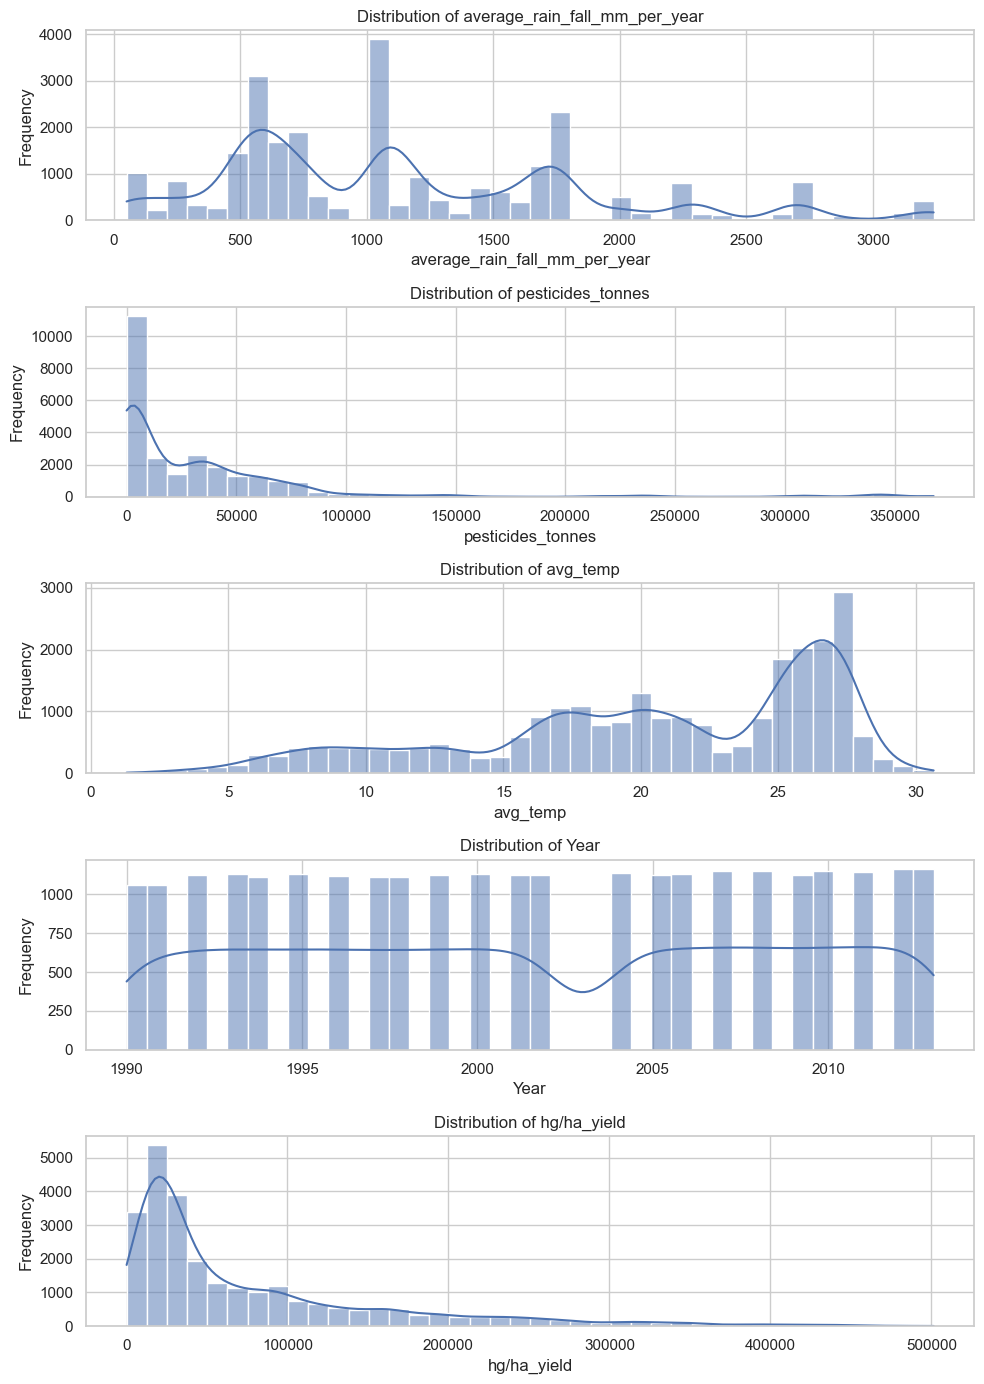

In [7]:
# Check numerical feature distributions after preprocessing

numeric_cols = [
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
    "Year",
    "hg/ha_yield"
]

fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(10, 14))

for i, col in enumerate(numeric_cols):
    sns.histplot(
        data=df_clean,
        x=col,
        bins=40,
        kde=True,
        ax=axes[i]
    )
    
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Observations

From the cleaned dataset distributions:

- `pesticides_tonnes` is still highly right-skewed.
- `hg/ha_yield` is also right-skewed and contains high-value observations.
- `avg_temp` shows a wider spread across different temperature ranges.
- `Year` is fairly evenly distributed across the available time period.
- The dataset is now cleaned, but skewness is still present in some numerical columns.

Since tree-based models can handle non-linear relationships and skewed data better than simple linear models, these features are kept unchanged for the next modelling stage.

## 6. Verify and Save the Cleaned Dataset

After preprocessing, we verify the final cleaned dataset before saving it.

In this step, we check:

- Whether any missing values remain
- Whether the target column is still available
- The final shape of the cleaned dataset
- Whether the cleaned CSV file is saved successfully

The cleaned dataset is saved as:

`data/crop_yield_cleaned.csv`

This file will be used in the model-building notebook.

In [9]:
# Verify cleaned dataset before saving

print("Cleaned Dataset Verification")
print("-" * 40)

# Check missing values
total_missing = df_clean.isnull().sum().sum()

print("Total missing values:", total_missing)
print("Target column present:", "hg/ha_yield" in df_clean.columns)
print("Final cleaned shape:", df_clean.shape)

# Save cleaned dataset
output_path = "../data/crop_yield_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("\nCleaned dataset saved successfully!")
print("Saved file path:", output_path)

Cleaned Dataset Verification
----------------------------------------
Total missing values: 0
Target column present: True
Final cleaned shape: (25932, 114)

Cleaned dataset saved successfully!
Saved file path: ../data/crop_yield_cleaned.csv


In [10]:
# Load saved cleaned dataset again to confirm it was saved correctly

saved_df = pd.read_csv("../data/crop_yield_cleaned.csv")

print("Saved dataset loaded successfully!")
print("Saved dataset shape:", saved_df.shape)

saved_df.head()

Saved dataset loaded successfully!
Saved dataset shape: (25932, 114)


,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,Area_Algeria,Area_Angola,Area_Argentina,Area_Armenia,Area_Australia,Area_Austria,Area_Azerbaijan,Area_Bahamas,Area_Bahrain,Area_Bangladesh,Area_Belarus,Area_Belgium,Area_Botswana,Area_Brazil,Area_Bulgaria,Area_Burkina Faso,Area_Burundi,Area_Cameroon,Area_Canada,Area_Central African Republic,Area_Chile,Area_Colombia,Area_Croatia,Area_Denmark,Area_Dominican Republic,Area_Ecuador,Area_Egypt,Area_El Salvador,Area_Eritrea,Area_Estonia,Area_Finland,Area_France,Area_Germany,Area_Ghana,Area_Greece,Area_Guatemala,Area_Guinea,Area_Guyana,Area_Haiti,Area_Honduras,Area_Hungary,Area_India,Area_Indonesia,Area_Iraq,Area_Ireland,Area_Italy,Area_Jamaica,Area_Japan,Area_Kazakhstan,Area_Kenya,Area_Latvia,Area_Lebanon,Area_Lesotho,Area_Libya,Area_Lithuania,Area_Madagascar,Area_Malawi,Area_Malaysia,Area_Mali,Area_Mauritania,Area_Mauritius,Area_Mexico,Area_Montenegro,Area_Morocco,Area_Mozambique,Area_Namibia,Area_Nepal,Area_Netherlands,Area_New Zealand,Area_Nicaragua,Area_Niger,Area_Norway,Area_Pakistan,Area_Papua New Guinea,Area_Peru,Area_Poland,Area_Portugal,Area_Qatar,Area_Romania,Area_Rwanda,Area_Saudi Arabia,Area_Senegal,Area_Slovenia,Area_South Africa,Area_Spain,Area_Sri Lanka,Area_Sudan,Area_Suriname,Area_Sweden,Area_Switzerland,Area_Tajikistan,Area_Thailand,Area_Tunisia,Area_Turkey,Area_Uganda,Area_Ukraine,Area_United Kingdom,Area_Uruguay,Area_Zambia,Area_Zimbabwe,Item_Maize,Item_Plantains and others,Item_Potatoes,"Item_Rice, paddy",Item_Sorghum,Item_Soybeans,Item_Sweet potatoes,Item_Wheat,Item_Yams
0,1990,36613,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1,1990,66667,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,1990,23333,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,1990,12500,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,1990,7000,1485.0,121.0,16.37,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


### Final Cleaning Summary

The data cleaning and preprocessing stage is now complete.

Completed tasks:

- Loaded the original crop yield dataset
- Checked missing values
- Identified duplicate rows
- Removed duplicate records
- Encoded categorical columns using one-hot encoding
- Converted the dataset into numerical format
- Saved the cleaned dataset for model building

The final cleaned dataset contains **25,932 rows** and **114 columns**.

This cleaned file will be used in the next notebook for machine learning model training and evaluation.